# Home Credit: baseline, вклад истории и вероятности

В первом сравнении Logistic Regression дала ROC-AUC 0,645 и предупреждение о сходимости. Такой результат был плохой отправной точкой для сравнения с CatBoost. В новом эксперименте числовые признаки масштабируются после заполнения пропусков, категории кодируются one-hot, а C выбирается из 0.1 и 1.0. Class weights убраны: здесь оцениваю ранжирование и вероятности, а порог решения не задаю.

Полный запуск находится в `src/credit_scoring/experiment.py`. Ноутбук использует сохранённые результаты этого запуска, поэтому графики можно воспроизвести без повторного обучения.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().parent
REPORTS = ROOT / "reports/portfolio"
plt.rcParams.update({"figure.figsize": (9, 4), "axes.spines.top": False,
                     "axes.spines.right": False})


## Разбиение

20% клиентов оставлены для итогового сравнения. Это тот же состав, который уже использовался в первой версии проекта, поэтому я не считаю его новым независимым тестом. Остальные данные разделены на обучение (60% всех клиентов) и калибровку (20%). На обучающей части используются три одинаковых стратифицированных фолда. Импутация, масштабирование и кодирование в Logistic Regression обучаются внутри фолда.

CatBoost заранее зафиксирован: 500 деревьев, глубина 6, learning rate 0.05. Для сравнения групп признаков параметры не меняются. Основной вариант — все группы; калибровка рассматривается отдельно. Дат заявок в открытых данных нет, поэтому это случайное, а не временное разбиение.

In [2]:
settings = json.loads((REPORTS / "experiment.json").read_text())
pd.Series(settings).to_frame("value")

,value
seed,42
cv_folds,3
catboost_iterations,500
catboost_depth,6
catboost_learning_rate,0.05
logistic_C,0.1
platform,macOS-26.3.1-arm64-arm-64bit
train_rows,184506
calibration_rows,61502
holdout_rows,61503


In [3]:
cv = pd.read_csv(REPORTS / "cv_results.csv")
summary = cv.groupby(["model", "group", "C"], dropna=False).agg(
    roc_auc_mean=("roc_auc", "mean"), roc_auc_std=("roc_auc", "std"),
    ap_mean=("average_precision", "mean"), ap_std=("average_precision", "std"),
    fit_seconds_mean=("fit_seconds", "mean"), iterations_max=("iterations", "max"),
)
summary.round(4)

roc_auc_mean  roc_auc_std  ap_mean  ap_std  \
model    group              C                                                 
catboost all_history        NaN        0.7825       0.0025   0.2742  0.0026   
         application        NaN        0.7610       0.0014   0.2450  0.0012   
         application_bureau NaN        0.7672       0.0021   0.2542  0.0014   
logistic all_history        0.1        0.7675       0.0022   0.2477  0.0021   
                            1.0        0.7672       0.0021   0.2473  0.0019   

                                 fit_seconds_mean  iterations_max  
model    group              C                                      
catboost all_history        NaN           63.5335             500  
         application        NaN          121.4353             500  
         application_bureau NaN           67.9296             500  
logistic all_history        0.1            5.5380              94  
                            1.0            9.0644             117

Линейная модель теперь сходится за десятки или сотню итераций. Масштабирование важно для оптимизатора и для того, чтобы регуляризация не зависела от единиц измерения признака. Этот запуск также отличается от первого кодированием ORGANIZATION_TYPE, отсутствием весов классов и размером обучающей части; всю разницу метрик нельзя приписать одному изменению.

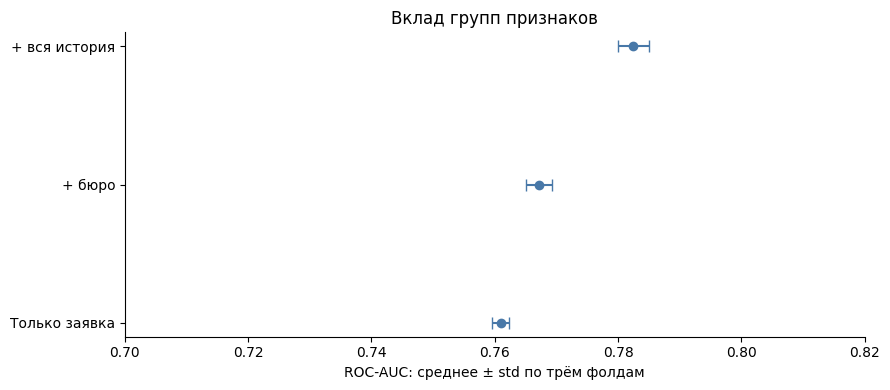

In [4]:
ablation = cv.query("model == 'catboost'").groupby("group").roc_auc.agg(["mean", "std"])
ablation = ablation.reindex(["application", "application_bureau", "all_history"])
fig, ax = plt.subplots()
ax.errorbar(ablation["mean"], range(3), xerr=ablation["std"], fmt="o", capsize=4, color="#4878a8")
ax.set_yticks(range(3), ["Только заявка", "+ бюро", "+ вся история"])
ax.set(xlabel="ROC-AUC: среднее ± std по трём фолдам", title="Вклад групп признаков")
ax.set_xlim(0.70, 0.82)
plt.tight_layout()
plt.show()

In [5]:
holdout = pd.read_csv(REPORTS / "holdout_metrics.csv")
holdout.round(5)

,model,features,fit_seconds,roc_auc,average_precision,brier
0,logistic_all_history,226,7.85948,0.77291,0.26344,0.06681
1,catboost_application,125,92.71307,0.76829,0.25873,0.06708
2,catboost_application_bureau,141,89.56281,0.77246,0.26987,0.06661
3,catboost_all_history,226,98.06836,0.78588,0.28703,0.06571
4,catboost_calibrated,226,NaN,0.78588,0.28703,0.06569


ROC-AUC показывает, как модель упорядочивает клиентов по риску. Average Precision дополнительно смотрю из-за редкого TARGET=1: положительных примеров около 8%. Здесь AP рассчитана через average_precision_score, без трапецеидального интегрирования PR-кривой.

## Калибровка

Для полного CatBoost отдельно обучена логистическая калибровка от logit исходной вероятности. Она видела только calibration-часть. На holdout сравниваю Brier score и наблюдаемую частоту TARGET=1 по десяти группам риска. В каждую группу попадает примерно одинаковое число клиентов.

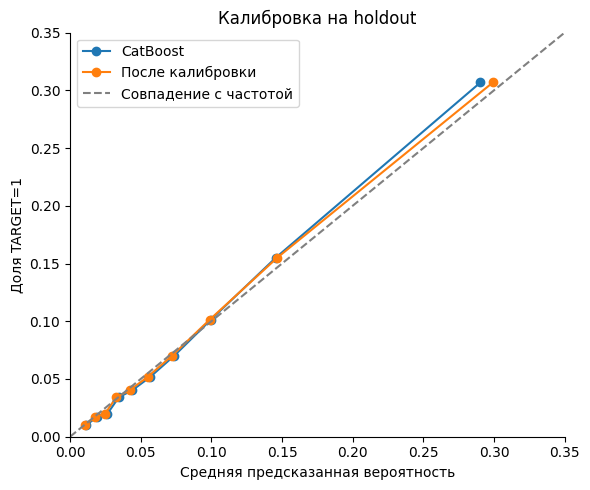

In [6]:
fig, ax = plt.subplots(figsize=(6, 5))
for name, label in [("catboost_all_history", "CatBoost"), ("catboost_calibrated", "После калибровки")]:
    deciles = pd.read_csv(REPORTS / f"{name}_deciles.csv")
    ax.plot(deciles.mean_probability, deciles.default_rate, marker="o", label=label)
ax.plot([0, 0.35], [0, 0.35], "--", color="gray", label="Совпадение с частотой")
ax.set(xlabel="Средняя предсказанная вероятность", ylabel="Доля TARGET=1",
       title="Калибровка на holdout", xlim=(0, 0.35), ylim=(0, 0.35))
ax.legend()
plt.tight_layout()
plt.show()

In [7]:
pd.read_csv(REPORTS / "catboost_calibrated_deciles.csv").round(4)

,decile,clients,default_rate,mean_probability,defaults
0,1,6151,0.0104,0.0105,64
1,2,6150,0.0171,0.0180,105
2,3,6150,0.0200,0.0248,123
3,4,6150,0.0341,0.0327,210
4,5,6151,0.0403,0.0423,248
5,6,6150,0.0517,0.0548,318
6,7,6150,0.0702,0.0723,432
7,8,6150,0.1015,0.0989,624
8,9,6150,0.1551,0.1467,954
9,10,6151,0.3068,0.2992,1887


## Клиенты с разной глубиной истории

Отдельно смотрю клиентов с историей бюро и без неё. У групп отличаются и частота TARGET=1, и число клиентов, поэтому разница AP сама по себе не доказывает, что одной группе модель подходит лучше.

In [8]:
segments = pd.read_csv(REPORTS / "history_segments.csv")
segments.query("model == 'catboost_all_history' and history == 'HAS_BUREAU_HISTORY'").round(4)

,model,history,present,clients,default_rate,roc_auc,average_precision,brier
0,catboost_all_history,HAS_BUREAU_HISTORY,0,8776,0.1014,0.7703,0.3228,0.0803
1,catboost_all_history,HAS_BUREAU_HISTORY,1,52727,0.0773,0.7874,0.2794,0.0633


## Что получилось

Исправленный линейный baseline получил на holdout ROC-AUC **0,7729** вместо 0,6451 в первом исследовании. Это не сравнение одного изменения: кроме масштабирования изменились кодирование, веса классов и размер train.

У CatBoost средний CV ROC-AUC вырос с **0,7610** по заявке до **0,7672** с бюро и **0,7825** с полной историей. На holdout полный вариант получил **ROC-AUC 0,7859** и **AP 0,2870**. Значит, дополнительные таблицы дали полезный сигнал при одинаковых параметрах модели.

Калибровка изменила Brier score с **0,065711** до **0,065691**. Выигрыш небольшой, а порядок клиентов и метрики ранжирования сохранились. Для этого набора основной результат — проверка вероятностей и понятный масштаб эффекта, а не заметный рост качества от дополнительного шага.

Порог одобрения кредита здесь не выбираю: в данных нет стоимости ошибок, условий продукта и доходности кредитов. Временную устойчивость тоже не проверял: календарных дат заявок в наборе нет.